# Capstone EDA: quarterly company financials

**Question:** using what a company reported up to the end of a quarter, can I predict its **revenue** and **profit margin** for the next quarter?

- **Who uses it:** an analyst who wants an early estimate before the next quarterly report is published.
- **One row:** one company in one quarter (`cik` + `period_end`).
- **Targets:** next quarter revenue (in log) and next quarter profit margin (net income / revenue). 
- **When the prediction is made:** right after quarter *t* is reported. Only values from quarter *t* or earlier can be features.

Data: quarterly figures from SEC filings (10-Q and 10-K) for 400 US listed companies, 2018 to 2026. Source: SEC EDGAR Company Facts API, https://www.sec.gov/search-filings/edgar-application-programming-interfaces. File built on 9 November 2026.

> **Changed 17 Nov 2026:** financial sector (30 companies) excluded in `clean_data`, see section 4. Notebook re-run on the same data; numbers in the text are updated. Notes marked 📝 explain each step .

## 1. Setup

Imports, one seed, file paths and the start.....

#### 📝 Note
**What:** load the libraries and set the basic settings.
- `SEED = 50`: the same random numbers on every run, so results are always the same.
- `TARGETS`: the two things I predict, revenue and margin next quarter.
- `TEST_START`: quarters from 2025 go to test, everything earlier goes to train.
- `EXCLUDE_FINANCIALS`: list of 30 banks, brokers and insurers that I remove.

**Why:** all key decisions are in one place, so they are easy to change.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 50

DATA_URL = "raw_data_400.csv"   # the file sits in this location
ID_COLS = ["cik", "period_end"]
TARGETS = ["log_revenue_next", "profit_margin_next"]
TEST_START = "2025-01-01"   # quarters ending on or after this date are the test set

# Financial sector excluded from scope (see section 4, "Scope: financial sector excluded")
EXCLUDE_FINANCIALS = {
    "banks":     ["BAC", "WFC", "USB", "PNC", "KEY", "CFG", "HBAN", "COF", "BNY", "STT", "NTRS"],
    "brokers":   ["SCHW", "RJF", "IBKR"],
    "insurers":  ["AIG", "AFL", "MET", "PRU", "PFG", "CB", "TRV", "ALL", "ACGL", "CINF",
                  "L", "GL", "AIZ", "EG", "WRB", "ERIE"],
}
EXCLUDE_TICKERS = [t for group in EXCLUDE_FINANCIALS.values() for t in group]

FIG_DIR = Path("figures")
OUT_DIR = Path("outputs")
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.3


## 2. Load and first look

Load the file and take a first look. `raw` stays untouched, I work on `df`. 13,966 rows, 66 columns and 400 unique companies. `revenue` and the dates are loaded as text.

#### 📝 Note
**What:** load the file and look at it.
- `raw` is the original and I never change it. I work on a copy, `df`.
- I remove spaces from column names, because the `revenue` column has a space before and after its name.

**Result:** 13,966 rows, 66 columns and 400 unique companies. `revenue` is loaded as text, not as a number.

**Why:** before any work I need to know what is in the file and in what form.

In [2]:
raw = pd.read_csv(DATA_URL)
df = raw.copy()
df.columns = df.columns.str.strip()

print(df.shape)
print("unique companies:", df["cik"].nunique())
df.info()
df.sample(5, random_state=SEED)

(13966, 66)
unique companies: 400
<class 'pandas.DataFrame'>
RangeIndex: 13966 entries, 0 to 13965
Data columns (total 66 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cik                          13966 non-null  int64  
 1   ticker                       13966 non-null  str    
 2   company                      13966 non-null  str    
 3   period_start                 13966 non-null  str    
 4   period_end                   13966 non-null  str    
 5   calendar_year                13966 non-null  int64  
 6   calendar_quarter             13966 non-null  int64  
 7   revenue                      13592 non-null  str    
 8   cost_of_revenue              8778 non-null   float64
 9   gross_profit                 5912 non-null   float64
 10  operating_income             10847 non-null  float64
 11  net_income                   13966 non-null  float64
 12  pretax_income                13002 non-null  float6

,cik,ticker,company,period_start,period_end,calendar_year,calendar_quarter,revenue,cost_of_revenue,gross_profit,operating_income,net_income,pretax_income,income_tax_expense,research_development,selling_general_admin,operating_expenses,interest_expense,eps_basic,eps_diluted,shares_basic,shares_diluted,assets,current_assets,noncurrent_assets,liabilities,current_liabilities,noncurrent_liabilities,equity,equity_including_minority,liabilities_and_equity,cash,cash_restricted,receivables,inventory,ppe_net,goodwill,intangibles_net,accounts_payable,retained_earnings,treasury_stock,short_term_borrowings,long_term_debt_current,long_term_debt_noncurrent,deferred_revenue_current,operating_cash_flow,investing_cash_flow,financing_cash_flow,capex,acquisitions_cash,depreciation_amortization,stock_compensation,dividends_paid,share_repurchases,debt_repayments,debt_issued,income_taxes_paid,interest_paid,dividend_per_share,shares_outstanding,revenue_concept,net_income_method,core_available,balance_identity_difference,balance_identity_status,free_cash_flow
348,318154,AMGN,Amgen Inc.,4/1/2026,6/30/2026,2026,2,"10,054,000,000.00",2.811000e+09,NaN,3.514000e+09,2.375000e+09,2.768000e+09,393000000.0,NaN,1.745000e+09,NaN,NaN,4.40,4.37,540000000.0,544000000.0,9.563900e+10,3.496100e+10,NaN,NaN,2.550200e+10,NaN,1.168800e+10,NaN,9.563900e+10,1.398900e+10,1.398900e+10,1.022700e+10,6.220000e+09,8.547000e+09,1.866800e+10,1.977700e+10,2.865000e+09,-2.227500e+10,NaN,NaN,5.445000e+09,5.185900e+10,NaN,4.002000e+09,-569000000.0,-1.482000e+09,513000000.0,NaN,1.112000e+09,165000000.0,1.362000e+09,NaN,0.0,0.0,NaN,NaN,2.520,540600000.0,RevenueFromContractWithCustomerExcludingAssess...,reported,1,0.0,pass,3.489000e+09
2527,827054,MCHP,MICROCHIP TECHNOLOGY INC,7/1/2020,9/30/2020,2020,3,"1,309,500,000.00",5.016000e+08,8.079000e+08,2.262000e+08,7.360000e+07,8.880000e+07,15200000.0,199800000.0,1.447000e+08,5.817000e+08,9.330000e+07,0.14,0.14,512000000.0,535300000.0,1.677090e+10,2.122100e+09,NaN,NaN,1.975200e+09,NaN,5.443700e+09,NaN,1.677090e+10,3.683000e+08,3.683000e+08,9.037000e+08,6.614000e+08,8.221000e+08,6.664800e+09,NaN,2.169000e+08,3.443900e+09,4.670000e+08,NaN,9.961000e+08,8.181400e+09,NaN,4.558000e+08,-41700000.0,-4.240000e+08,6300000.0,NaN,2.858000e+08,49700000.0,NaN,NaN,NaN,NaN,NaN,NaN,0.184,260254947.0,RevenueFromContractWithCustomerExcludingAssess...,reported,1,0.0,pass,4.495000e+08
2647,1262039,FTNT,"FORTINET, INC.",4/1/2024,6/30/2024,2024,2,"1,434,300,000.00",2.750000e+08,1.159300e+09,4.372000e+08,3.798000e+08,4.683000e+08,76500000.0,165400000.0,NaN,7.221000e+08,5.000000e+06,0.50,0.49,763800000.0,769900000.0,8.052900e+09,4.919300e+09,NaN,7.764700e+09,3.725300e+09,NaN,2.882000e+08,2.882000e+08,8.052900e+09,2.203200e+09,2.203200e+09,1.083400e+09,3.832000e+08,1.242700e+09,1.279000e+08,3.020000e+07,1.321000e+08,-1.182600e+09,NaN,NaN,NaN,9.933000e+08,2.975300e+09,3.420000e+08,-50100000.0,-1.400000e+07,23100000.0,0.0,2.920000e+07,63900000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,764200000.0,RevenueFromContractWithCustomerExcludingAssess...,reported,1,0.0,pass,3.189000e+08
13223,1381197,IBKR,"INTERACTIVE BROKERS GROUP, INC.",1/1/2024,3/31/2024,2024,1,"438,000,000.00",NaN,NaN,NaN,7.950000e+08,8.660000e+08,71000000.0,NaN,5.000000e+07,NaN,1.013000e+09,1.63,1.61,107070830.0,108149440.0,1.322380e+11,NaN,NaN,1.175790e+11,NaN,NaN,3.732000e+09,1.465900e+10,1.322380e+11,4.063000e+09,3.402400e+10,NaN,NaN,NaN,NaN,NaN,NaN,2.016000e+09,3.000000e+06,NaN,NaN,NaN,NaN,1.683000e+09,-13000000.0,-1.370000e+08,NaN,NaN,1.700000e+07,28000000.0,1.100000e+07,NaN,NaN,NaN,32000000.0,1.006000e+09,NaN,NaN,RevenueFromContractWithCustomerExcludingAssess...,reported,1,0.0,pass,NaN
8152,1075531,BKNG,Booking Holdings Inc.,10/1/2021,12/31/2021,2021,4,"2,981,000,000.00",NaN,NaN,8.480000e+08,6.180000e+08,8.160000e+08,198000000.0,NaN,NaN,2.133000e+09,7.500000e+07,NaN,NaN,NaN,NaN,2.364100e+10,1.314500e+10,NaN,1.746300e+10,6.246000e+09,NaN,6.178000e+09,NaN,2.364100e+10,1.112700e+10,1.115200e+10,NaN,NaN,8.220000e+08,2.

Revenue is in text needs to be numeric

#### 📝 Note
**What:** check how revenue is written as text.

**Result:**
- numbers have commas and spaces, e.g. `" 61,137,000,000.00 "`
- 35 values are in brackets, the accounting way to write a negative number
  (35 negative revenues at 21 companies; most are in the last quarter of the fiscal year)
- 3 values are just a dash, meaning no data

**Why:** I need to know these rules to turn the text into numbers correctly.

In [3]:

print(df["revenue"].head(3).tolist())
print(df.loc[df["revenue"].str.contains(r"\(", na=False), "revenue"].head(3).tolist())
print("values in brackets:", df["revenue"].str.contains(r"\(", na=False).sum())
print("just a dash:", (df["revenue"].str.strip() == "-").sum())

[' 61,137,000,000.00 ', ' 53,265,000,000.00 ', ' 62,900,000,000.00 ']
[' (3,544,000,000.00)', ' (3,858,000,000.00)', ' (866,000,000.00)']
values in brackets: 35
just a dash: 3


## 3. Data dictionary and missingness

Type, unique values and missing share of every column. The key `cik` + `period_end` is unique. Many columns are missing in 40% or more of the rows. I keep a small set of core columns that almost every company reports.

#### 📝 Note
**What:** build a data dictionary: for each column, its type, number of distinct values and how much is missing.
- every one of the 66 columns gets a short meaning; the `assert` checks that none is left out
- I also check that `cik` + `period_end` is unique (one company, one quarter, one row).

**Result:** every company has 34 or 35 quarters. Many columns are missing in 40% or more of rows.

**Why:** columns that most companies do not report are not useful for the model. I keep a small set of core columns that almost every company reports (revenue, net income, operating cash flow, assets, equity, cash) and drop the rest, including some that are fairly complete (e.g. pretax income, retained earnings), to keep the model simple.

In [4]:
meaning = {
    # identifiers and time
    "cik": "SEC company id (Central Index Key)",
    "ticker": "stock ticker",
    "company": "company name",
    "period_start": "first day of the quarter",
    "period_end": "last day of the quarter",
    "calendar_year": "calendar year of the quarter",
    "calendar_quarter": "calendar quarter 1-4",
    # income statement (flows in the quarter, USD)
    "revenue": "revenue in the quarter, USD (stored as text)",
    "cost_of_revenue": "cost of goods or services sold, USD",
    "gross_profit": "revenue minus cost of revenue, USD",
    "operating_income": "profit from operations before interest and tax, USD",
    "net_income": "net income in the quarter, USD",
    "pretax_income": "profit before income tax, USD",
    "income_tax_expense": "income tax expense, USD",
    "research_development": "research and development expense, USD",
    "selling_general_admin": "selling, general and administrative expense, USD",
    "operating_expenses": "total operating expenses, USD",
    "interest_expense": "interest expense on debt, USD",
    "eps_basic": "earnings per share, basic, USD",
    "eps_diluted": "earnings per share, diluted, USD",
    "shares_basic": "average number of shares, basic",
    "shares_diluted": "average number of shares, diluted",
    # balance sheet (values at quarter end, USD)
    "assets": "total assets at quarter end, USD",
    "current_assets": "assets expected to turn into cash within a year, USD",
    "noncurrent_assets": "long-term assets, USD",
    "liabilities": "total liabilities, USD",
    "current_liabilities": "liabilities due within a year, USD",
    "noncurrent_liabilities": "long-term liabilities, USD",
    "equity": "shareholders equity at quarter end, USD",
    "equity_including_minority": "equity including minority (non-controlling) interests, USD",
    "liabilities_and_equity": "total liabilities plus equity (equals total assets), USD",
    "cash": "cash at quarter end, USD",
    "cash_restricted": "cash including restricted cash, USD",
    "receivables": "money owed by customers, USD",
    "inventory": "inventory, USD",
    "ppe_net": "property, plant and equipment after depreciation, USD",
    "goodwill": "goodwill from acquisitions, USD",
    "intangibles_net": "intangible assets after amortisation (excl. goodwill), USD",
    "accounts_payable": "money owed to suppliers, USD",
    "retained_earnings": "accumulated profits kept in the company, USD",
    "treasury_stock": "value of own shares bought back and held, USD",
    "short_term_borrowings": "short-term debt, USD",
    "long_term_debt_current": "part of long-term debt due within a year, USD",
    "long_term_debt_noncurrent": "long-term debt due after more than a year, USD",
    "deferred_revenue_current": "cash received for goods or services not yet delivered, USD",
    # cash flow statement (flows in the quarter, USD)
    "operating_cash_flow": "cash flow from operations, USD",
    "investing_cash_flow": "cash flow from investing (negative = net spending), USD",
    "financing_cash_flow": "cash flow from financing (debt, dividends, buybacks), USD",
    "capex": "capital expenditure: cash spent on property and equipment, USD",
    "acquisitions_cash": "cash paid for acquisitions of other companies, USD",
    "depreciation_amortization": "depreciation and amortisation, USD",
    "stock_compensation": "share-based pay to employees, USD",
    "dividends_paid": "dividends paid to shareholders, USD",
    "share_repurchases": "cash spent on buying back own shares, USD",
    "debt_repayments": "cash used to repay debt, USD",
    "debt_issued": "cash raised by new debt, USD",
    "income_taxes_paid": "income tax actually paid in cash, USD",
    "interest_paid": "interest actually paid in cash, USD",
    "free_cash_flow": "operating cash flow minus capex, USD",
    # per share and data quality fields from the download
    "dividend_per_share": "dividend declared per share, USD",
    "shares_outstanding": "number of shares outstanding at quarter end",
    "revenue_concept": "SEC tag the revenue was taken from (e.g. Revenues)",
    "net_income_method": "reported = quarter as filed; cumulative_difference = year-to-date minus previous quarters",
    "core_available": "1 = core fields (net income, assets) present; 1 in every row",
    "balance_identity_difference": "assets minus (liabilities + equity); 0 = balance sheet adds up",
    "balance_identity_status": "pass = balance sheet adds up, unavailable = cannot check",
}
assert set(meaning) == set(df.columns), set(df.columns) ^ set(meaning)

data_dict = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
})
data_dict["meaning"] = data_dict.index.map(meaning).fillna("")

assert not df.duplicated(ID_COLS).any()
print("quarters per company:", df.groupby("cik").size().min(), "to", df.groupby("cik").size().max())

data_dict.sort_values("pct_missing", ascending=False)

quarters per company: 34 to 35


,dtype,n_unique,n_missing,pct_missing,meaning
noncurrent_assets,float64,703,13263,95.0,"long-term assets, USD"
noncurrent_liabilities,float64,1591,12371,88.6,"long-term liabilities, USD"
operating_expenses,float64,2804,10987,78.7,"total operating expenses, USD"
short_term_borrowings,float64,2151,10692,76.6,"short-term debt, USD"
research_development,float64,2761,10269,73.5,"research and development expense, USD"
debt_issued,float64,2025,9134,65.4,"cash raised by new debt, USD"
long_term_debt_current,float64,2999,8839,63.3,"part of long-term debt due within a year, USD"
income_taxes_paid,float64,3096,8685,62.2,"income tax actually paid in cash, USD"
debt_repayments,float64,2460,8289,59.4,"cash used to repay debt, USD"
gross_profit,float64,5282,8054,57.7,"revenue minus cost of revenue, USD"


Who is missing revenue (2.7% of rows)? Mostly banks.

#### 📝 Note
**What:** check which companies have no revenue.

**Result:** almost all are large banks (Goldman Sachs, JPMorgan, Truist, Synchrony, Morgan Stanley, Regions, BNY). Banks do not report a "Revenues" line, so the value was not downloaded.

**Why it matters:** this is the first sign that "revenue" for banks is not the same thing as for other companies. That is why the next step removes the whole financial sector.

In [5]:
# who is missing revenue?
df[df["revenue"].isna()]["company"].value_counts().head(8)

company
The Goldman Sachs Group, Inc.              35
JPMORGAN CHASE & CO                        35
TRUIST FINANCIAL CORPORATION               35
SYNCHRONY FINANCIAL                        35
MORGAN STANLEY                             34
Regions Financial Corporation              34
THE BANK OF NEW YORK MELLON CORPORATION    33
XCEL ENERGY INC                            28
Name: count, dtype: int64

## 4. Clean

### Scope: financial sector excluded

**Banks (11), brokers (3) and insurers (16), 30 companies in total, are removed before cleaning.** List: `EXCLUDE_FINANCIALS` in Setup.

Why:
- **Revenue is not comparable.** For banks and brokers "revenue" is interest income net of interest expense plus fees, and companies report it under different tags. For insurers revenue includes gains and losses on investments, so it moves with markets, not with the business. Profit margin = net income / revenue therefore does not mean the same thing as for other companies.
- **The revenue tag is often wrong in this download.** Checked against published quarterly reports: e.g. KeyCorp Q3 2024 has 419 M USD in the file vs 695 M reported total revenue; Q1 2025 411 M vs 1,773 M. Margins come out 2-30x too high (KEY +0.99 instead of about +0.23).
- **The sector that remains is not representative.** The largest banks (JPMorgan, Goldman Sachs, Morgan Stanley, Truist, Synchrony, Regions) have no revenue at all and drop out anyway; the banks left are mostly the ones with a wrong revenue tag.
- **Errors sit in the tails.** Before the exclusion, wrong revenue was behind about 12% of extreme next-quarter margins and 29% of next-quarter revenue jumps > 65%, the cases that drive model error.

Consequence: **the model is for non-financial companies.** This is a scope decision, not a cleaning step, and is stated as a limitation.

Kept on purpose: payment companies (V, MA, PYPL, ...), exchanges and data providers (CME, ICE, SPGI, ...), insurance brokers (AON, AJG, ...), asset managers and REITs: their revenue is fee or rent based and comparable. Known single-company issues (BX, DOC, SBAC) are left in for now and handled separately.

Classification is manual (the file has no sector column). A cleaner source is the SIC code from SEC (banks and insurers are SIC 6000-6499).

One function does all the cleaning, so I can re-run it on a new download:

- drop the financial sector (30 companies, see above)
- revenue to number; negative revenue (33 rows) set to missing
- calendar quarter from the middle of the period, not from the last day
- profit margin = net income / revenue; margins outside -100% to +100% set to missing (403 rows). Note: this also removes real extreme quarters, e.g. cruise lines in 2020-2021, so the model has not seen the worst crises and they are not in the test set either
- features: log revenue, log assets, equity/assets, cash/assets, operating cash flow/revenue, revenue growth vs previous quarter and vs last year
- targets: next quarter log revenue and margin, with `shift(-1)` per company

No imputing or scaling here.

#### 📝 Note
**What:** all cleaning is in one function, so I can repeat it on a new download. Steps in order:

1. **Remove duplicates and tidy company names** (some names have hidden spaces).
2. **Remove 30 financial companies** (1,049 rows). Their revenue is not comparable with other companies (see the note above).
3. **Turn revenue from text into a number.** Brackets become minus, a dash becomes empty.
4. **Set revenue ≤ 0 to empty** (33 rows; the other 2 of the 35 belong to financial companies removed in step 2). Negative revenue is almost always an error from the yearly calculation, not real revenue: most cases fall in the last quarter of the fiscal year, where the quarter is likely computed as full year minus the first three quarters (e.g. ADM Q4 2022: −48 bn USD, while the quarters before and after are about +24 bn). A few may be real (e.g. Blackstone Q1 2020, when investment losses were booked as revenue), but log and margin cannot use negative revenue either way.
5. **Take the quarter from the middle of the period, not from the last day.** A quarter that ends on 1 July is Q2, not Q3.
6. **Add new columns:**
   - `profit_margin` = net income / revenue
   - `log_revenue`, `log_assets` = logarithm, so large and small companies are comparable
   - `equity_ratio`, `cash_ratio` = equity and cash as a share of assets
   - `ocf_margin` = cash flow from operations / revenue
7. **Set margins outside −100% to +100% to empty** (403 rows). This almost always means wrong revenue. Limitation: some real crises are removed too, e.g. cruise lines in 2020–21.
8. **Compute revenue growth and the targets with `shift`.**
   - `shift(1)` = previous quarter, `shift(4)` = same quarter last year, `shift(-1)` = next quarter (target).
   - This is done **before** dropping rows. Otherwise "next quarter" could be the quarter after a gap instead of the real next quarter.
9. **Drop rows without revenue, margin or target.** This also drops the last quarter of each company, because it has no next quarter.

**Result:** 13,966 → 11,682 rows, 400 → 357 companies.

**Note:** 24 rows are "same company twice in one calendar quarter". These are retailers with 12- and 16-week quarters (Kroger, AutoZone, Costco). Not a problem for the target, but their `calendar_quarter` is not exact.

In [6]:
KEEP = ["cik", "ticker", "company", "period_end", "calendar_year", "calendar_quarter",
        "revenue", "net_income", "operating_cash_flow", "assets", "equity", "cash"]

def clean_data(d):
    d = d.copy()
    d.columns = d.columns.str.strip()
    d = d.drop_duplicates()
    d["company"] = d["company"].str.replace("\xa0", " ", regex=False).str.strip()

    # scope: drop banks, brokers and insurers (revenue not comparable, see markdown above)
    is_fin = d["ticker"].isin(EXCLUDE_TICKERS)
    print("financial sector rows dropped:", is_fin.sum(), "| companies:", d.loc[is_fin, "cik"].nunique())
    d = d[~is_fin]

    # revenue: " 61,137,000,000.00 " -> 61137000000.0 , "(866,000,000.00)" -> negative
    rev = d["revenue"].astype(str).str.strip().str.replace(",", "", regex=False)
    rev = rev.str.replace("(", "-", regex=False).str.replace(")", "", regex=False)
    d["revenue"] = pd.to_numeric(rev, errors="coerce")
    not_positive = d["revenue"] <= 0
    d.loc[not_positive, "revenue"] = np.nan

    d["period_start"] = pd.to_datetime(d["period_start"], format="%m/%d/%Y")
    d["period_end"] = pd.to_datetime(d["period_end"], format="%m/%d/%Y")

    # calendar quarter from the middle of the period, not from the last day
    # (a quarter that ends on 1 July is a Q2, not a Q3)
    middle = d["period_start"] + (d["period_end"] - d["period_start"]) / 2
    d["calendar_year"] = middle.dt.year
    d["calendar_quarter"] = middle.dt.quarter

    d = d[KEEP].sort_values(["cik", "period_end"])

    d = d.assign(
        profit_margin=d["net_income"] / d["revenue"],
        log_revenue=np.log(d["revenue"]),
        log_assets=np.log(d["assets"]),
        equity_ratio=d["equity"] / d["assets"],
        cash_ratio=d["cash"] / d["assets"],
        ocf_margin=d["operating_cash_flow"] / d["revenue"],
    )

    # revenue is not reliable in these rows
    bad = d["profit_margin"].abs() > 1
    d.loc[bad, ["profit_margin", "log_revenue", "ocf_margin"]] = np.nan

    # shift before dropping rows, so shift(1) is always the previous quarter of that company
    by_company = d.groupby("cik")
    d["revenue_growth_qoq"] = d["log_revenue"] - by_company["log_revenue"].shift(1)
    d["revenue_growth_yoy"] = d["log_revenue"] - by_company["log_revenue"].shift(4)
    d["log_revenue_next"] = by_company["log_revenue"].shift(-1)
    d["profit_margin_next"] = by_company["profit_margin"].shift(-1)

    print("revenue <= 0 set to missing:", not_positive.sum())
    print("margin outside -1..1 set to missing:", bad.sum())
    print("same company twice in one calendar quarter:",
          d.duplicated(["cik", "calendar_year", "calendar_quarter"]).sum(), "rows")

    d = d.dropna(subset=["log_revenue", "profit_margin"] + TARGETS)
    return d.reset_index(drop=True)

df = clean_data(raw)

assert not df.duplicated(ID_COLS).any()
assert df["profit_margin"].between(-1, 1).all()

print("rows:", len(raw), "->", len(df))
print("companies:", raw["cik"].nunique(), "->", df["cik"].nunique())
df.head()

financial sector rows dropped: 1049 | companies: 30


revenue <= 0 set to missing: 33
margin outside -1..1 set to missing: 403
same company twice in one calendar quarter: 24 rows
rows: 13966 -> 11682
companies: 400 -> 357


,cik,ticker,company,period_end,calendar_year,calendar_quarter,revenue,net_income,operating_cash_flow,assets,equity,cash,profit_margin,log_revenue,log_assets,equity_ratio,cash_ratio,ocf_margin,revenue_growth_qoq,revenue_growth_yoy,log_revenue_next,profit_margin_next
0,1800,ABT,ABBOTT LABORATORIES,2018-03-31,2018,1,7.390000e+09,418000000.0,1.108000e+09,7.090800e+10,3.139900e+10,3.857000e+09,0.056563,22.723394,24.984649,0.442813,0.054394,0.149932,NaN,NaN,22.773150,0.094374
1,1800,ABT,ABBOTT LABORATORIES,2018-06-30,2018,2,7.767000e+09,733000000.0,1.244000e+09,6.841500e+10,3.057700e+10,3.065000e+09,0.094374,22.773150,24.948858,0.446934,0.044800,0.160165,0.049756,NaN,22.758755,0.073537
2,1800,ABT,ABBOTT LABORATORIES,2018-09-30,2018,3,7.656000e+09,563000000.0,2.183000e+09,7.163700e+10,3.070500e+10,7.369000e+09,0.073537,22.758755,24.994878,0.428619,0.102866,0.285136,-0.014394,NaN,22.772892,0.084224
3,1800,ABT,ABBOTT LABORATORIES,2018-12-31,2018,4,7.765000e+09,654000000.0,1.765000e+09,6.717300e+10,3.052400e+10,3.844000e+09,0.084224,22.772892,24.930537,0.454409,0.057225,0.227302,0.014137,NaN,22.742825,0.089184
4,1800,ABT,ABBOTT LABORATORIES,2019-03-31,2019,1,7.535000e+09,672000000.0,7.120000e+08,6.761000e+10,3.092500e+10,3.022000e+09,0.089184,22.742825,24.937022,0.457403,0.044698,0.094492,-0.030068,0.019431,22.800079,0.126081


### Data dictionary of the clean table

#### 📝 Note
**What:** the same kind of table for the clean data used in modelling: the 12 columns kept from the raw file, the 6 new columns made in `clean_data`, the 2 growth columns and the 2 targets.

**Why:** the new columns and the targets are not in the raw file, so their meaning and formula are written here. All of them use only quarter *t* or earlier, except the two targets, which are quarter *t+1*.

In [7]:
clean_meaning = {
    "cik": "SEC company id (Central Index Key)",
    "ticker": "stock ticker",
    "company": "company name",
    "period_end": "last day of the quarter",
    "calendar_year": "calendar year, taken from the middle of the quarter",
    "calendar_quarter": "calendar quarter 1-4, taken from the middle of the quarter",
    "revenue": "revenue in the quarter, USD (number; <= 0 set to missing)",
    "net_income": "net income in the quarter, USD",
    "operating_cash_flow": "cash flow from operations, USD",
    "assets": "total assets at quarter end, USD",
    "equity": "shareholders equity at quarter end, USD",
    "cash": "cash at quarter end, USD",
    "profit_margin": "net income / revenue (share; 0.12 = 12%)",
    "log_revenue": "natural log of revenue",
    "log_assets": "natural log of total assets",
    "equity_ratio": "equity / assets (share of assets financed by owners)",
    "cash_ratio": "cash / assets",
    "ocf_margin": "operating cash flow / revenue",
    "revenue_growth_qoq": "log revenue minus log revenue one quarter earlier (about % change)",
    "revenue_growth_yoy": "log revenue minus log revenue four quarters earlier (about % change)",
    "log_revenue_next": "TARGET 1: log revenue of the next quarter (shift(-1) per company)",
    "profit_margin_next": "TARGET 2: profit margin of the next quarter (shift(-1) per company)",
}
assert set(clean_meaning) == set(df.columns), set(df.columns) ^ set(clean_meaning)

clean_dict = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
})
clean_dict["meaning"] = clean_dict.index.map(clean_meaning)
clean_dict

,dtype,n_missing,pct_missing,meaning
cik,int64,0,0.0,SEC company id (Central Index Key)
ticker,str,0,0.0,stock ticker
company,str,0,0.0,company name
period_end,datetime64[us],0,0.0,last day of the quarter
calendar_year,int32,0,0.0,"calendar year, taken from the middle of the qu..."
calendar_quarter,int32,0,0.0,"calendar quarter 1-4, taken from the middle of..."
revenue,float64,0,0.0,"revenue in the quarter, USD (number; <= 0 set ..."
net_income,float64,0,0.0,"net income in the quarter, USD"
operating_cash_flow,float64,223,1.9,"cash flow from operations, USD"
assets,float64,0,0.0,"total assets at quarter end, USD"


### Split before looking

Split by time before any EDA: train = quarters ending before 2025, test = 2025 and later (about 18% of rows). From here on every chart and statistic uses train only.

#### 📝 Note
**What:** split the data into train and test by time.
- train = quarters before 2025 (9,627 rows)
- test = 2025 and later (2,055 rows, 17.6%)

**Why by time, not at random:** in real use the model predicts the future from the past. A random split would let the model "see the future" and the result would look too good.

**Why before the analysis:** all charts and statistics use train only, so the test set does not influence my decisions.

In [8]:
train = df[df["period_end"] < TEST_START].copy()
test = df[df["period_end"] >= TEST_START].copy()

assert train["period_end"].max() < test["period_end"].min()
print("train:", train.shape, "|", train["period_end"].min().date(), "to", train["period_end"].max().date())
print("test: ", test.shape, "|", test["period_end"].min().date(), "to", test["period_end"].max().date())
print("test share:", round(len(test) / len(df), 3))

train: (9627, 22) | 2018-01-26 to 2024-12-31
test:  (2055, 22) | 2025-01-24 to 2026-07-05
test share: 0.176


## 5. Univariate EDA

Raw revenue is extremely right skewed (a few giants). Log revenue is close to symmetric, so I model log revenue.

#### 📝 Note
**What:** compare the distribution of revenue in dollars and in log.

**Result:** in dollars almost everything is squeezed to the left, with a few giants far to the right. In log the distribution is almost symmetric, like a bell.

**Why:** models work better when the target is not this skewed. So I predict log revenue, not revenue in dollars.

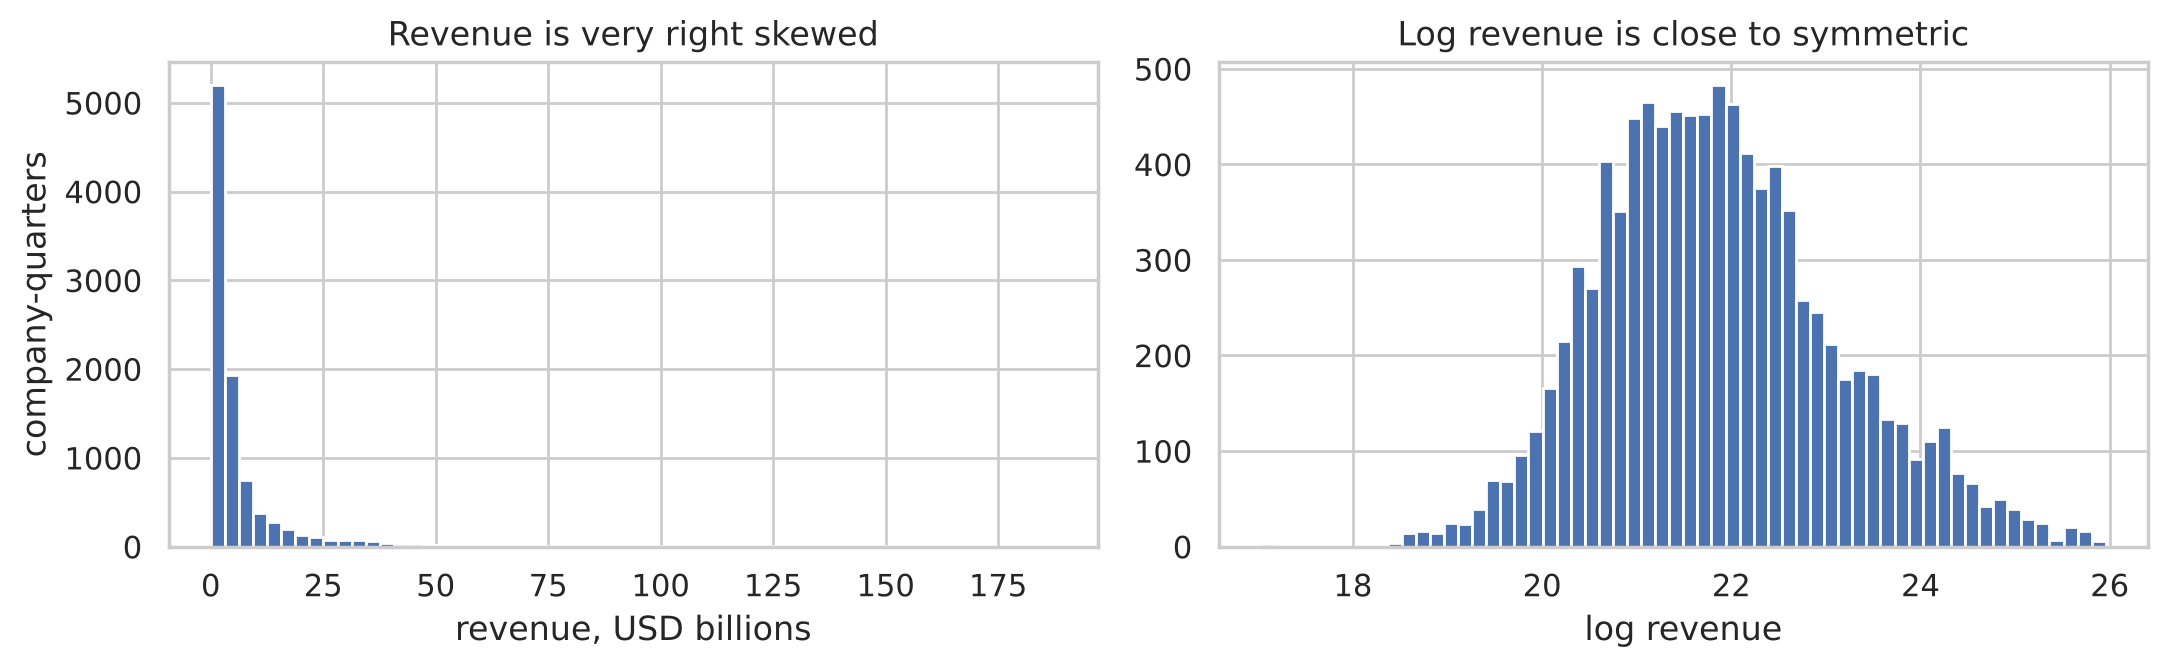

In [9]:
num_cols = ["log_revenue", "profit_margin", "revenue_growth_qoq", "revenue_growth_yoy",
            "log_assets", "equity_ratio", "cash_ratio", "ocf_margin"]
cat_cols = ["calendar_quarter"]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
(train["revenue"] / 1e9).hist(bins=60, ax=ax[0])
ax[0].set_title("Revenue is very right skewed")
ax[0].set_xlabel("revenue, USD billions")
ax[0].set_ylabel("company-quarters")
train["log_revenue"].hist(bins=60, ax=ax[1])
ax[1].set_title("Log revenue is close to symmetric")
ax[1].set_xlabel("log revenue")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_revenue_raw_vs_log.png", dpi=120)
plt.show()

Distribution of every numeric feature. Margin is centred around 12%, growth vs previous quarter near +2%. `ocf_margin` and `equity_ratio` have a few extreme values. Because of the skew I report medians.

#### 📝 Note
**What:** histogram of every numeric column and a table of basic statistics.

**Result:**
- typical margin is about 12%
- typical revenue growth is about +2% per quarter
- `ocf_margin` has extremes (max 12.7: cash flow 12 times revenue)
- `equity_ratio` has negative values (companies with negative equity, e.g. after share buybacks)

**Why:** because of the extremes I report medians, not means. The median is not sensitive to extremes.

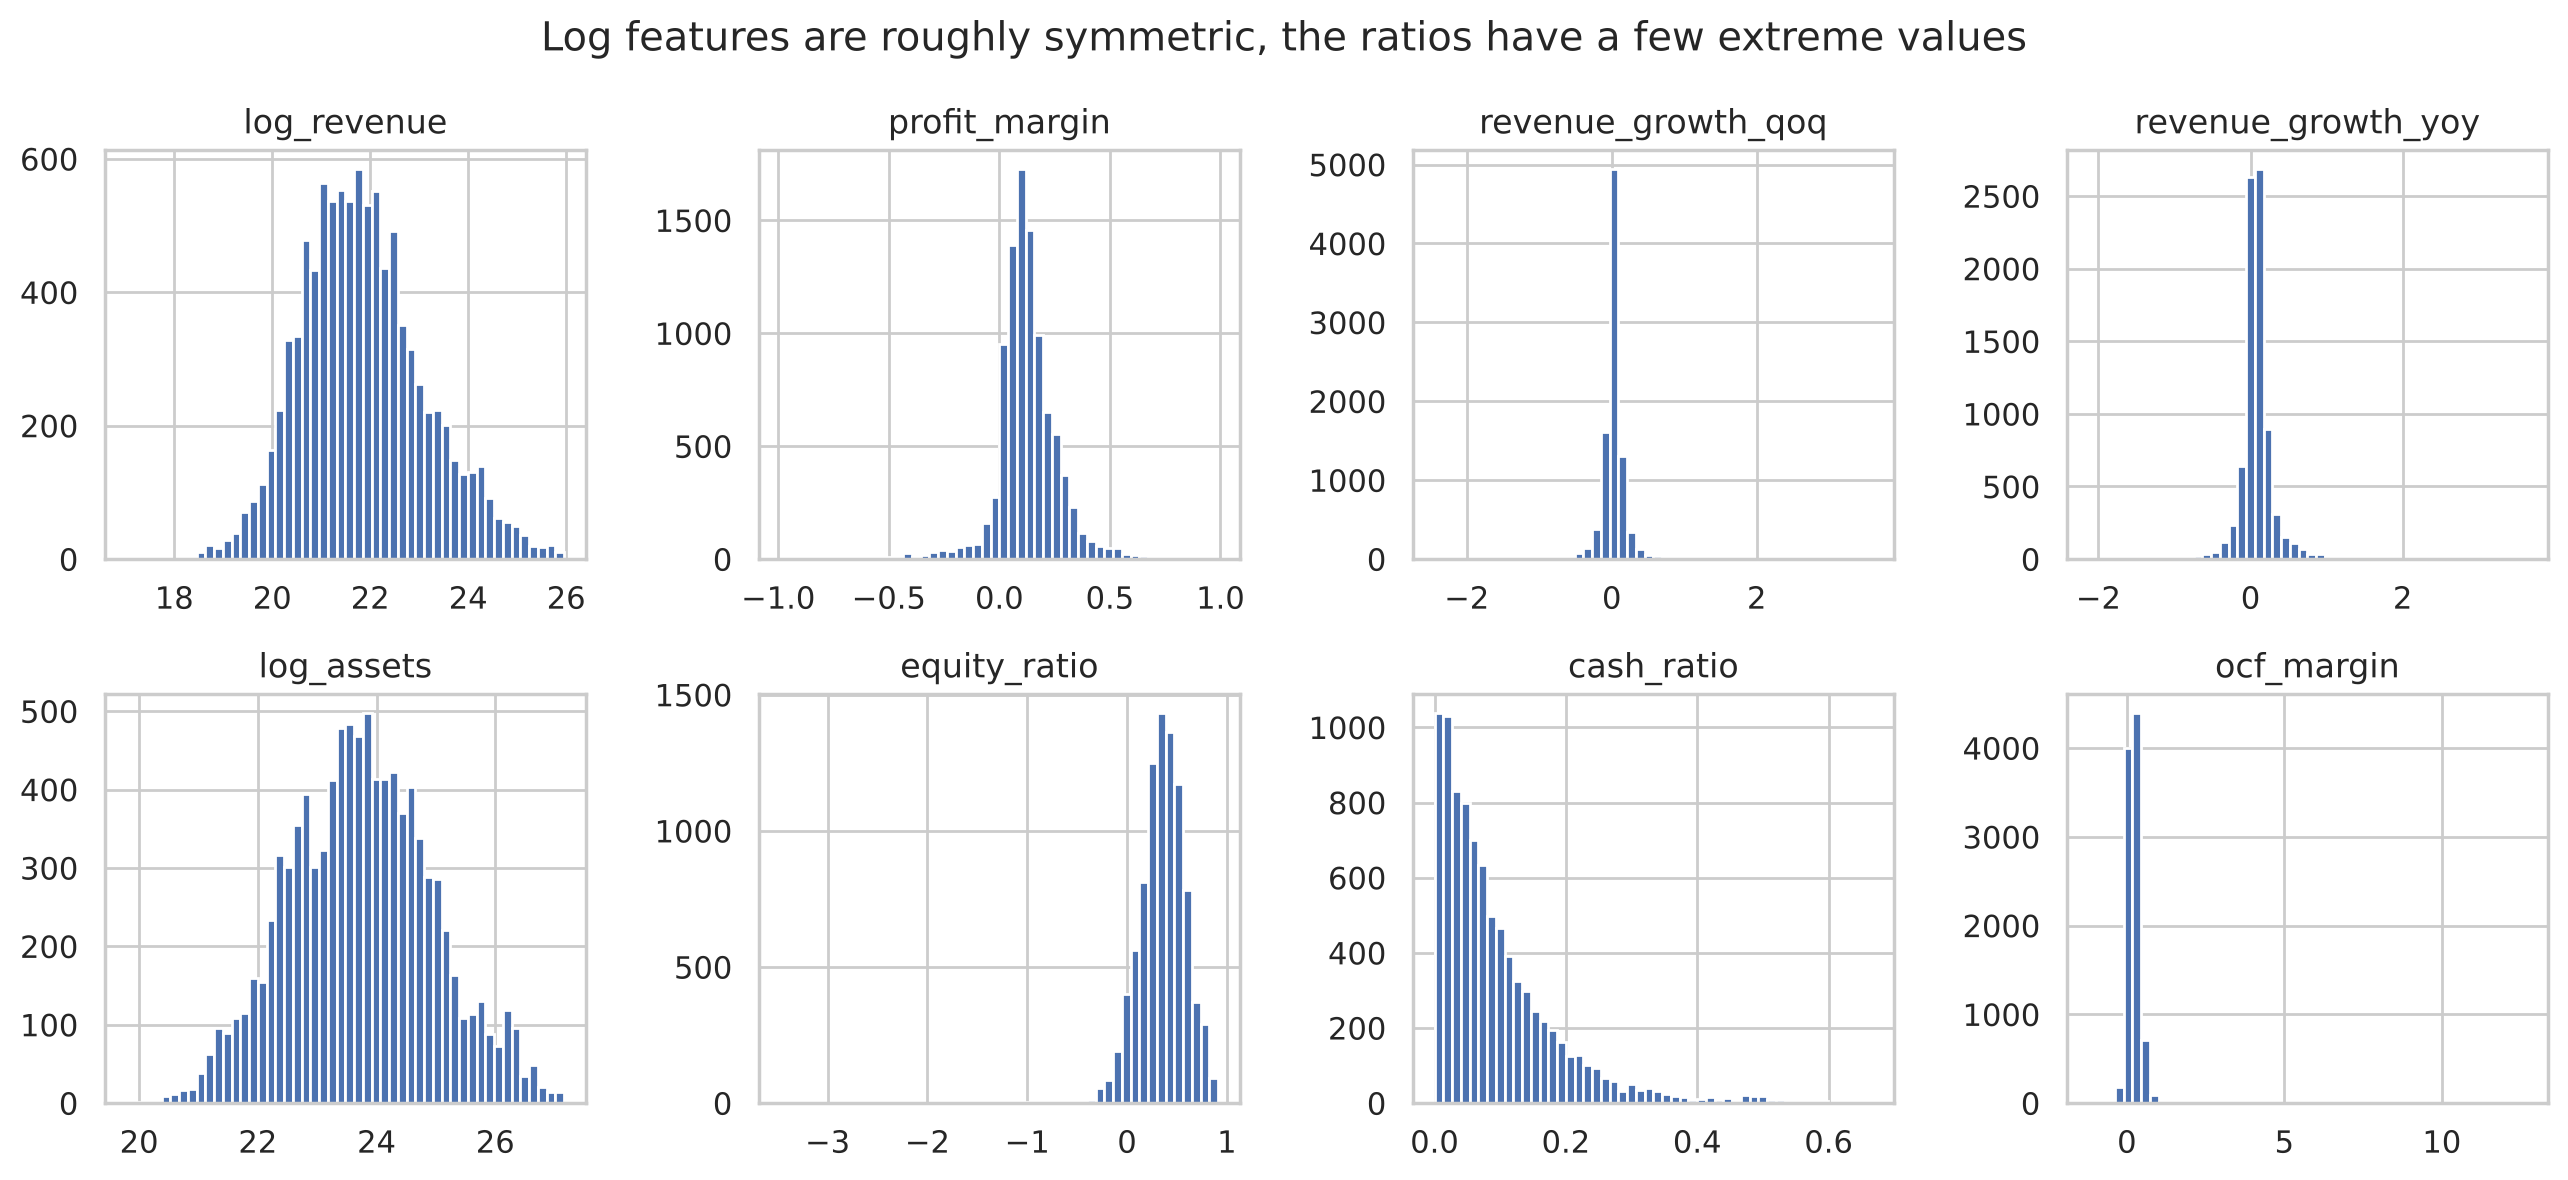

,count,mean,std,min,25%,50%,75%,max
log_revenue,9627.0,21.852,1.267,17.027,20.973,21.761,22.596,25.959
profit_margin,9627.0,0.126,0.151,-0.989,0.058,0.117,0.191,0.990
revenue_growth_qoq,9167.0,0.022,0.204,-2.443,-0.030,0.022,0.076,3.592
revenue_growth_yoy,8140.0,0.077,0.250,-2.129,-0.003,0.065,0.145,3.623
log_assets,9627.0,23.742,1.217,19.789,22.857,23.728,24.565,27.161
equity_ratio,8969.0,0.337,0.301,-3.471,0.214,0.363,0.507,0.913
cash_ratio,8818.0,0.094,0.093,0.000,0.029,0.067,0.129,0.666
ocf_margin,9448.0,0.220,0.280,-1.216,0.097,0.193,0.303,12.677


In [10]:
train[num_cols].hist(bins=50, figsize=(13, 6), layout=(2, 4))
plt.suptitle("Log features are roughly symmetric, the ratios have a few extreme values")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_numeric_features.png", dpi=120)
plt.show()

train[num_cols].describe().T.round(3)

Rows per quarter are balanced. About 9% of rows are loss quarters.

#### 📝 Note
**What:** count rows per quarter and the share of loss quarters.

**Result:** quarters are evenly represented (about 2,400 each). 8.8% of quarters are losses.

**Why:** if one quarter were much rarer, the model would learn it worse.

In [11]:
print(train["calendar_quarter"].value_counts().sort_index())
print("share of loss quarters:", round((train["profit_margin"] < 0).mean(), 3))

calendar_quarter
1    2433
2    2404
3    2393
4    2397
Name: count, dtype: int64
share of loss quarters: 0.088


## 6. Targets and relationships

Both targets look like their current quarter versions: the same variable one quarter later.

#### 📝 Note
**What:** look at both targets.

**Result:**
- log revenue: almost symmetric
- margin: very narrow around 10–12%, but with long tails, especially towards losses

**Why it matters:** for margin, the error depends mostly on rare extreme cases. That is why I use MAE, which is less sensitive to extremes than RMSE.

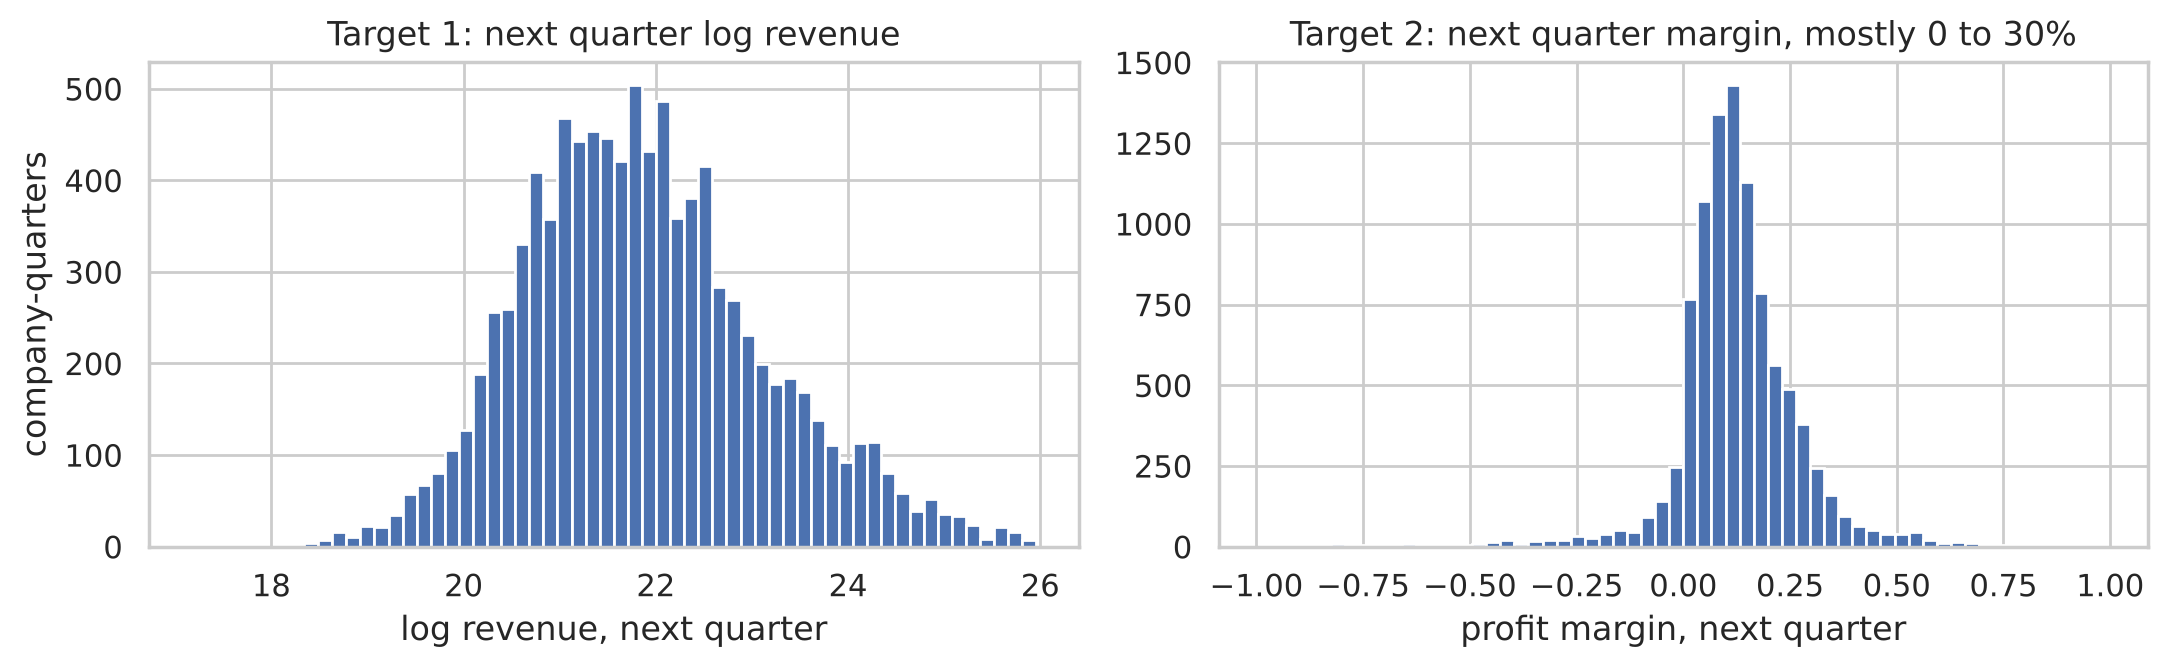

,count,mean,std,min,25%,50%,75%,max
log_revenue_next,9627.0,21.872,1.26,17.168,20.994,21.781,22.610,25.959
profit_margin_next,9627.0,0.126,0.15,-0.989,0.058,0.117,0.191,0.990


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
train["log_revenue_next"].hist(bins=60, ax=ax[0])
ax[0].set_title("Target 1: next quarter log revenue")
ax[0].set_xlabel("log revenue, next quarter")
ax[0].set_ylabel("company-quarters")
train["profit_margin_next"].hist(bins=60, ax=ax[1])
ax[1].set_title("Target 2: next quarter margin, mostly 0 to 30%")
ax[1].set_xlabel("profit margin, next quarter")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_targets.png", dpi=120)
plt.show()

train[TARGETS].describe().T.round(3)

Target vs the same variable this quarter. Revenue is almost on the diagonal, margin is much noisier, so margin is the harder target.

#### 📝 Note
**What:** plot each target against the same value this quarter.

**Result:**
- revenue: points sit almost on the diagonal, so revenue barely changes from one quarter to the next
- margin: there is a link, but much more spread

**Why:** this shows revenue is an easy target and margin is a hard one. Any model must beat the simple rule "next quarter = this quarter".

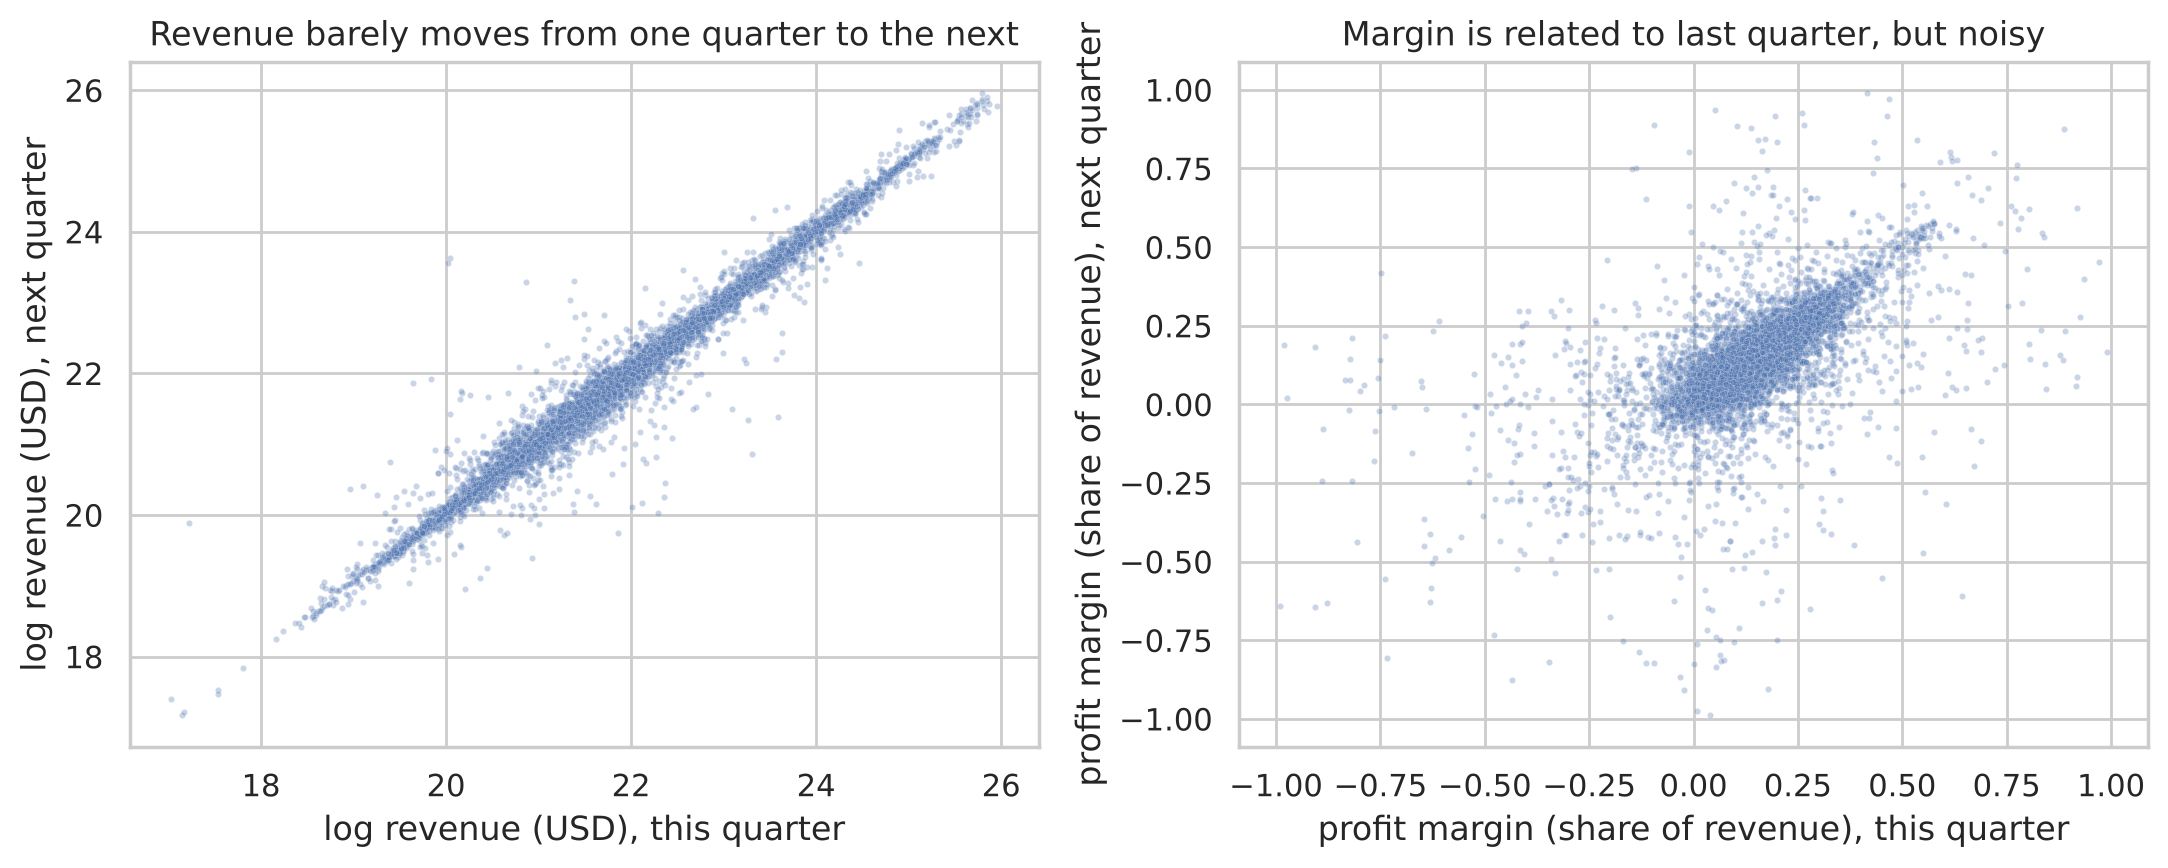

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sns.scatterplot(data=train, x="log_revenue", y="log_revenue_next", s=5, alpha=0.3, ax=ax[0])
ax[0].set_title("Revenue barely moves from one quarter to the next")
ax[0].set_xlabel("log revenue (USD), this quarter")
ax[0].set_ylabel("log revenue (USD), next quarter")
sns.scatterplot(data=train, x="profit_margin", y="profit_margin_next", s=5, alpha=0.3, ax=ax[1])
ax[1].set_title("Margin is related to last quarter, but noisy")
ax[1].set_xlabel("profit margin (share of revenue), this quarter")
ax[1].set_ylabel("profit margin (share of revenue), next quarter")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_target_vs_current.png", dpi=120)
plt.show()

Correlation of each feature with the targets: 0.99 for revenue with next revenue, 0.60 for margin with next margin, 0.31 for operating cash flow margin with next margin. Growth features are weak. These are associations, not causes.

#### 📝 Note
**What:** correlation of each column with both targets.

**Result:**
- revenue now ↔ revenue next: 0.99
- margin now ↔ margin next: 0.60
- `ocf_margin` ↔ margin next: 0.31
- revenue growth: close to zero

**Why:** shows which columns carry signal. Correlation means a link, not a cause.

In [14]:
corr_target = train[num_cols + TARGETS].corr()[TARGETS].drop(TARGETS)
corr_target.sort_values("profit_margin_next", key=abs, ascending=False).round(2)

,log_revenue_next,profit_margin_next
profit_margin,-0.09,0.60
ocf_margin,-0.19,0.31
log_revenue,0.99,-0.09
revenue_growth_yoy,-0.01,0.09
equity_ratio,-0.12,0.05
cash_ratio,-0.14,0.05
revenue_growth_qoq,0.00,0.03
log_assets,0.81,0.01


Seasonality: median revenue growth is about -0.8% in Q1 and +2% to +4% in the other quarters. For margin the quarter makes almost no difference.

#### 📝 Note
**What:** check if the quarter of the year affects revenue growth and margin.

**Result:** revenue usually falls a little in Q1 (−0.8%) and grows 2–4% in the other quarters. The quarter has almost no effect on margin.

**Why:** if there is seasonality, the model needs the `calendar_quarter` column.

In [15]:
train.groupby("calendar_quarter")[["revenue_growth_qoq", "profit_margin_next"]].median().round(3)

,revenue_growth_qoq,profit_margin_next
calendar_quarter,,
1,-0.008,0.117
2,0.038,0.122
3,0.022,0.116
4,0.026,0.113


## 7. Correlation, redundancy and leakage check

Correlation between all features, and a leakage check. `log_revenue` and `log_assets` move together (both measure size). The only feature above 0.9 with a target is `log_revenue`. That is not leakage: this quarter's revenue is known when the prediction is made. It does mean R² will look great for any model, so I will compare against the "same as last quarter" baseline.

#### 📝 Note
**What:** plot correlations between all columns and check for leakage.

**Result:**
- `log_revenue` and `log_assets` move together (0.81), because both measure company size
- the only column above 0.9 with a target is `log_revenue`

**Why this is not leakage:** this quarter's revenue is known when the prediction is made. But because of it, R² will look great for any model, so I compare models with the naive rule instead of looking at R².

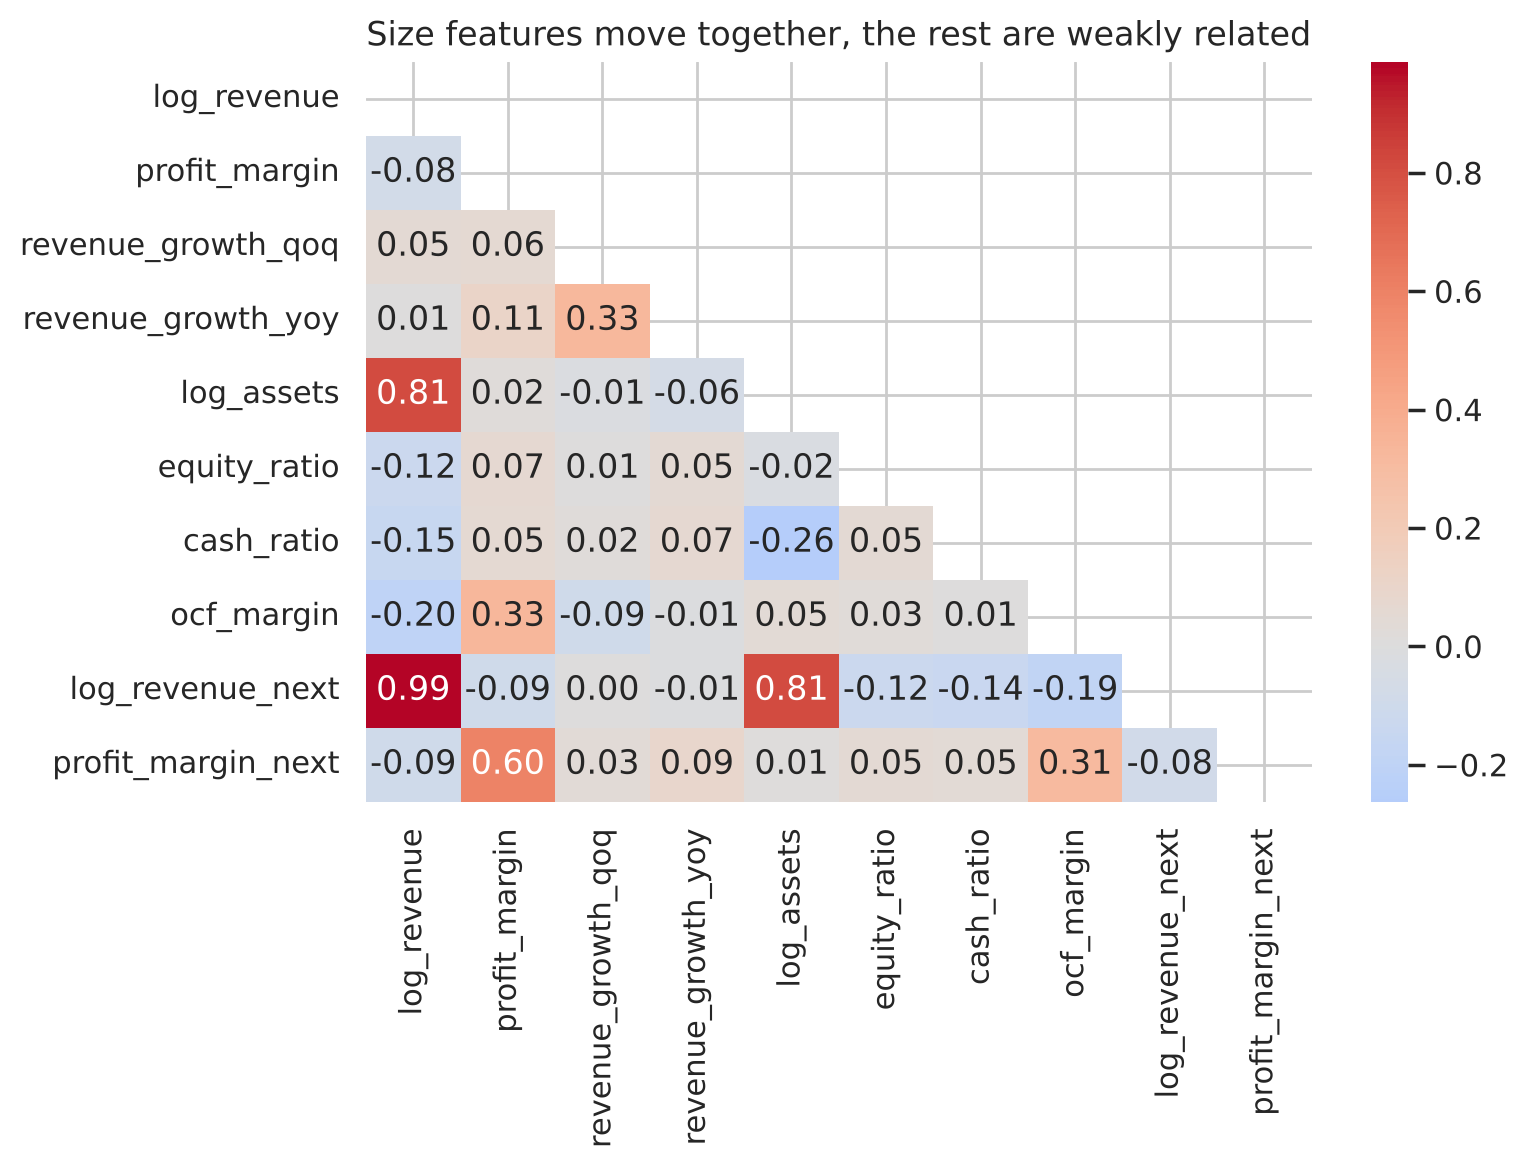

log_revenue_next -> features with |r| > 0.9: ['log_revenue']
profit_margin_next -> features with |r| > 0.9: []


In [16]:
corr = train[num_cols + TARGETS].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Size features move together, the rest are weakly related")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_correlation.png", dpi=120)
plt.show()

for target in TARGETS:
    c = corr[target].drop(TARGETS).abs()
    print(target, "-> features with |r| > 0.9:", c[c > 0.9].index.tolist())

### Outliers, risks and next steps

**Outliers: how I checked them and what I did**
- **Profit margin:** values outside −100% to +100% (403 rows) were inspected by company and quarter. Most come from an incomplete revenue tag, some are real crises (cruise lines 2020–21). Set to missing in `clean_data` (section 4).
- **Negative revenue** (33 rows): almost always full year minus three quarters in the 10-K. Set to missing (section 4).
- **`equity_ratio` below 0** (6.9% of train rows, 46 companies, minimum −3.47 for Domino's): real values. These companies have negative equity after large share buybacks (e.g. Domino's, Home Depot, AutoZone, Boeing). **Kept.**
- **`ocf_margin` above 1** (55 train rows, maximum 12.7 for SBA Communications): cash flow many times revenue. Mostly a few real estate and tower companies (SBAC, INVH) where revenue looks incomplete. **Kept** but noted: there are few of them, MAE is not dominated by single rows, and tree models are not pulled by extremes.

**What I found**
- Revenue is very persistent (r = 0.99 with next quarter in log); margin much less (r = 0.60). Any model must beat "next quarter = this quarter".
- Q1 revenue usually falls a little (−0.8%), the other quarters grow 2–4%: seasonality matters for revenue, almost not for margin.
- Operating cash flow margin carries extra signal for next margin (r = 0.31).

**Risks and limits of the data**
- Non-financial companies only (30 banks, brokers and insurers excluded).
- Survivorship bias: the company list is a recent S&P 500 snapshot, so failed or delisted firms are missing.
- The most extreme quarters were removed (margins outside ±100%), so the model will not learn the worst crises, and the test set does not contain them either (test error describes normal and moderately bad quarters).
- Revenue tags from the SEC download are sometimes wrong; checked by hand only for the largest problems.
- Only accounting data: no sector, macro data or news.

**Next steps (for the modelling notebook)**
1. **Baselines first:** a null model (train median) and naive persistence (next = this quarter), with MAE as the main metric.
2. **Features from the company's own history:** last quarter's margin, the 4-quarter average margin and last year's seasonal revenue step, built with `groupby` + `shift` so only past quarters are used.
3. **Compare three model families** (linear with regularisation, random forest, gradient boosting) in pipelines with median imputation inside, tuned with `GridSearchCV` on company folds (`GroupKFold`), and test once on 2025 onwards.

## 8. Save outputs and record decisions

Save the clean table as `clean final.csv` in the project folder (the file the modelling notebook reads) and the list of decisions to `outputs/decisions.csv`.

#### 📝 Note
**What:** save the clean table `clean final.csv` (with a `split` column) in the project folder, and the list of all decisions `outputs/decisions.csv`.

**Why:** the modelling notebook starts from these files. The list of decisions makes it easy to explain in the report what was done and why.

In [17]:
split = np.where(df["period_end"] < TEST_START, "train", "test")
df.assign(split=split).to_csv("clean final.csv", index=False)   # the file 02_modelling_.ipynb reads

decisions = pd.DataFrame([
    ("grain", "one row = one company in one quarter, key cik + period_end"),
    ("targets", "next quarter log revenue and next quarter profit margin, built with shift(-1) per company"),
    ("columns", "kept a small set of core columns reported by almost all companies; dropped the rest"),
    ("revenue parsing", "text to number; brackets = negative; dash = missing"),
    ("negative revenue", "33 rows set to missing, not plausible"),
    ("financial sector", "30 banks, brokers and insurers excluded: revenue not comparable and often wrong tag; model scope = non-financial companies"),
    ("margin outside -1..1", "set to missing; mostly incomplete revenue tags, but also real crises (e.g. cruise lines 2020-21); removed from train and test -> limitation"),
    ("calendar quarter", "taken from the middle of the period, not from the last day"),
    ("log transform", "revenue and assets are very right skewed"),
    ("missing values", "median imputation + missing flag inside the pipeline, not before the split"),
    ("split", "by time: train before 2025, test 2025 and later; split before EDA, EDA on train only"),
    ("cross-validation", "GroupKFold by company"),
    ("metric", "MAE; R2 is misleading for revenue because of persistence"),
    ("baseline to beat", "naive: next quarter = this quarter"),
], columns=["step", "decision"])
decisions.to_csv(OUT_DIR / "decisions.csv", index=False)
decisions

,step,decision
0,grain,"one row = one company in one quarter, key cik ..."
1,targets,next quarter log revenue and next quarter prof...
2,columns,kept a small set of core columns reported by a...
3,revenue parsing,text to number; brackets = negative; dash = mi...
4,negative revenue,"33 rows set to missing, not plausible"
5,financial sector,"30 banks, brokers and insurers excluded: reven..."
6,margin outside -1..1,set to missing; mostly incomplete revenue tags...
7,calendar quarter,"taken from the middle of the period, not from ..."
8,log transform,revenue and assets are very right skewed
9,missing values,median imputation + missing flag inside the pi...


## 9. Appendix: libraries, course code and data sources

**Libraries**
- pandas (data loading, cleaning, groupby and shift): https://pandas.pydata.org/docs/
- NumPy (log transform, arrays): https://numpy.org/doc/stable/
- matplotlib (charts): https://matplotlib.org/stable/
- seaborn (scatter plots, heatmap, theme): https://seaborn.pydata.org/
- scikit-learn (used later, in `02_modelling_.ipynb`): https://scikit-learn.org/stable/

Versions used: printed in section 1 (pandas 3.0.5, NumPy 2.5.3).

**Course code this notebook follows** (General Assembly DSB)
- Unit 2 capstone EDA template (structure of this notebook): https://github.com/CharleyHananiaGA/DSB-Unit-02/blob/main/assets/capstone-eda-template.ipynb
- Unit 2 code-along 2.5: advanced pandas transformations (groupby + shift): https://github.com/CharleyHananiaGA/DSB-Unit-02/blob/main/99%20-%20Stepped%20Code-Along/Module%202.5%20-%20Advanced%20pandas%20Transformations.ipynb
- Unit 2 glossary: capstone playbook, the data stage: https://github.com/CharleyHananiaGA/DSB-Unit-02/blob/main/Readme.MD#s00-capstone-playbook-the-data-stage
- Unit 2 glossary: capstone code cookbook: https://github.com/CharleyHananiaGA/DSB-Unit-02/blob/main/Readme.MD#s00b-capstone-code-cookbook

**Data**
- SEC EDGAR application programming interfaces (Company Facts API, quarterly figures from 10-Q and 10-K filings): https://www.sec.gov/search-filings/edgar-application-programming-interfaces
- SEC rules for accessing EDGAR data: https://www.sec.gov/search-filings/edgar-search-assistance/accessing-edgar-data
- Files in this repository: raw download `raw_data_400.csv` (400 companies, built on 9 November 2026), cleaned table `clean final.csv` (written by `01_EDA_clean final.ipynb`, section 8, and read by `02_modelling_.ipynb`).
- SEC EDGAR data is public U.S. government information. It contains company figures only, no personal data.

**Capstone guidelines:** https://github.com/juanatga/ga_capstone_guideline_dsb